# EDA y entrenamiento de SVM y Random Forest

> **Actualización 26/11/2026.** Este cuaderno se volvió a ejecutar con la base ampliada (332 imágenes, 31 grupos; ver `docs/revision_base_v1.md`). Conserva su protocolo original de tres bloques agrupados como referencia histórica. La evaluación con prueba independiente y las mejoras están en el cuaderno 09.

**Objetivo:** explorar la base vigente y comparar dos clasificadores de **calidad externa**: buena, intermedia y mala, para manzana roja, banano y limón.

Usamos las imágenes y máscaras ya revisadas. Las dudas pendientes conservan sus grupos actuales y no impiden este primer experimento. Un único modelo predice la calidad para las tres frutas a partir de **43 características de imagen**, sin usar fruta, fuente, rutas o identificadores como entradas.

**Diseño fijado antes de entrenar:** tres pliegues con `StratifiedGroupKFold`, semilla 42 y los mismos grupos para todos los modelos; SVM con escalado dentro del entrenamiento, Random Forest y referencia mayoritaria. Priorizamos F1 macro y recall macro por el desbalance. No ajustamos hiperparámetros con estos resultados.

Esta es una comparación exploratoria de desarrollo: el procesamiento de las imágenes ya se revisó con este lote. No constituye una prueba final independiente.

In [1]:
from pathlib import Path
import json
import sys

# Buscar la raíz por archivos versionados, sin exigir datos generados.
candidatos = [Path.cwd(), *Path.cwd().parents]
candidatos += [p / 'proyecto_estado_frutas' for p in candidatos.copy()]
PROYECTO = next((p for p in candidatos if (p / 'config/alcance_actual.json').is_file() and (p / 'src').is_dir()), None)
if PROYECTO is None:
    raise FileNotFoundError('Abrir el cuaderno desde la carpeta del proyecto o notebooks/.')
if str(PROYECTO) not in sys.path:
    sys.path.insert(0, str(PROYECTO))

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src.models.modelos_tradicionales import (
    cargar_base, hacer_eda, crear_pliegues, entrenar_y_comparar, CALIDADES,
)

SALIDA = PROYECTO / 'experiments/results/eda_modelos'
CHECKPOINTS = PROYECTO / 'experiments/checkpoints/modelos_tradicionales'
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
base, columnas, estado = cargar_base(PROYECTO)
print(f'Base vigente: {len(base)} imágenes, {len(columnas)} características, {base.grupo_particion.nunique()} grupos.')
print('SHA de la base:', estado['sha_base'])

Base vigente: 332 imágenes, 43 características, 31 grupos.
SHA de la base: bf1bbae08894ae929e36ed7926968cd74dbb0a01a50c3fc05c3aa9a2042137c3


## 1. Integridad, balance y procedencia

Verificamos valores faltantes, duplicados y características constantes. Contamos tanto imágenes como grupos: varias fotografías del mismo fruto o campaña no equivalen a observaciones independientes. Los campos vacíos de identidad no son características del modelo.

,valor
imagenes,332
caracteristicas,43
grupos_conservadores,31
faltantes_caracteristicas,0
caracteristicas_constantes,[]
filas_caracteristicas_duplicadas,0
sha_original_repetidos,0
fraccion_clase_mayoritaria,0.6295
alcance_tamano,Las formas y tamaños son relativos a la imagen...


calidad_revisada,buena,intermedia,mala,total
fruta,,,,
manzana,123,6,7,136
banano,10,77,14,101
limon,76,11,8,95


,fruta,calidad_revisada,fotos,grupos
0,banano,buena,10,4
1,banano,intermedia,77,3
2,banano,mala,14,6
3,limon,buena,76,5
4,limon,intermedia,11,5
5,limon,mala,8,3
6,manzana,buena,123,11
7,manzana,intermedia,6,3
8,manzana,mala,7,4


calidad_revisada,buena,intermedia,mala
fuente,,,
propia,15,2,8
propia_lote_20261126,8,19,14
publica,178,67,0
publica_kaggle,8,6,7


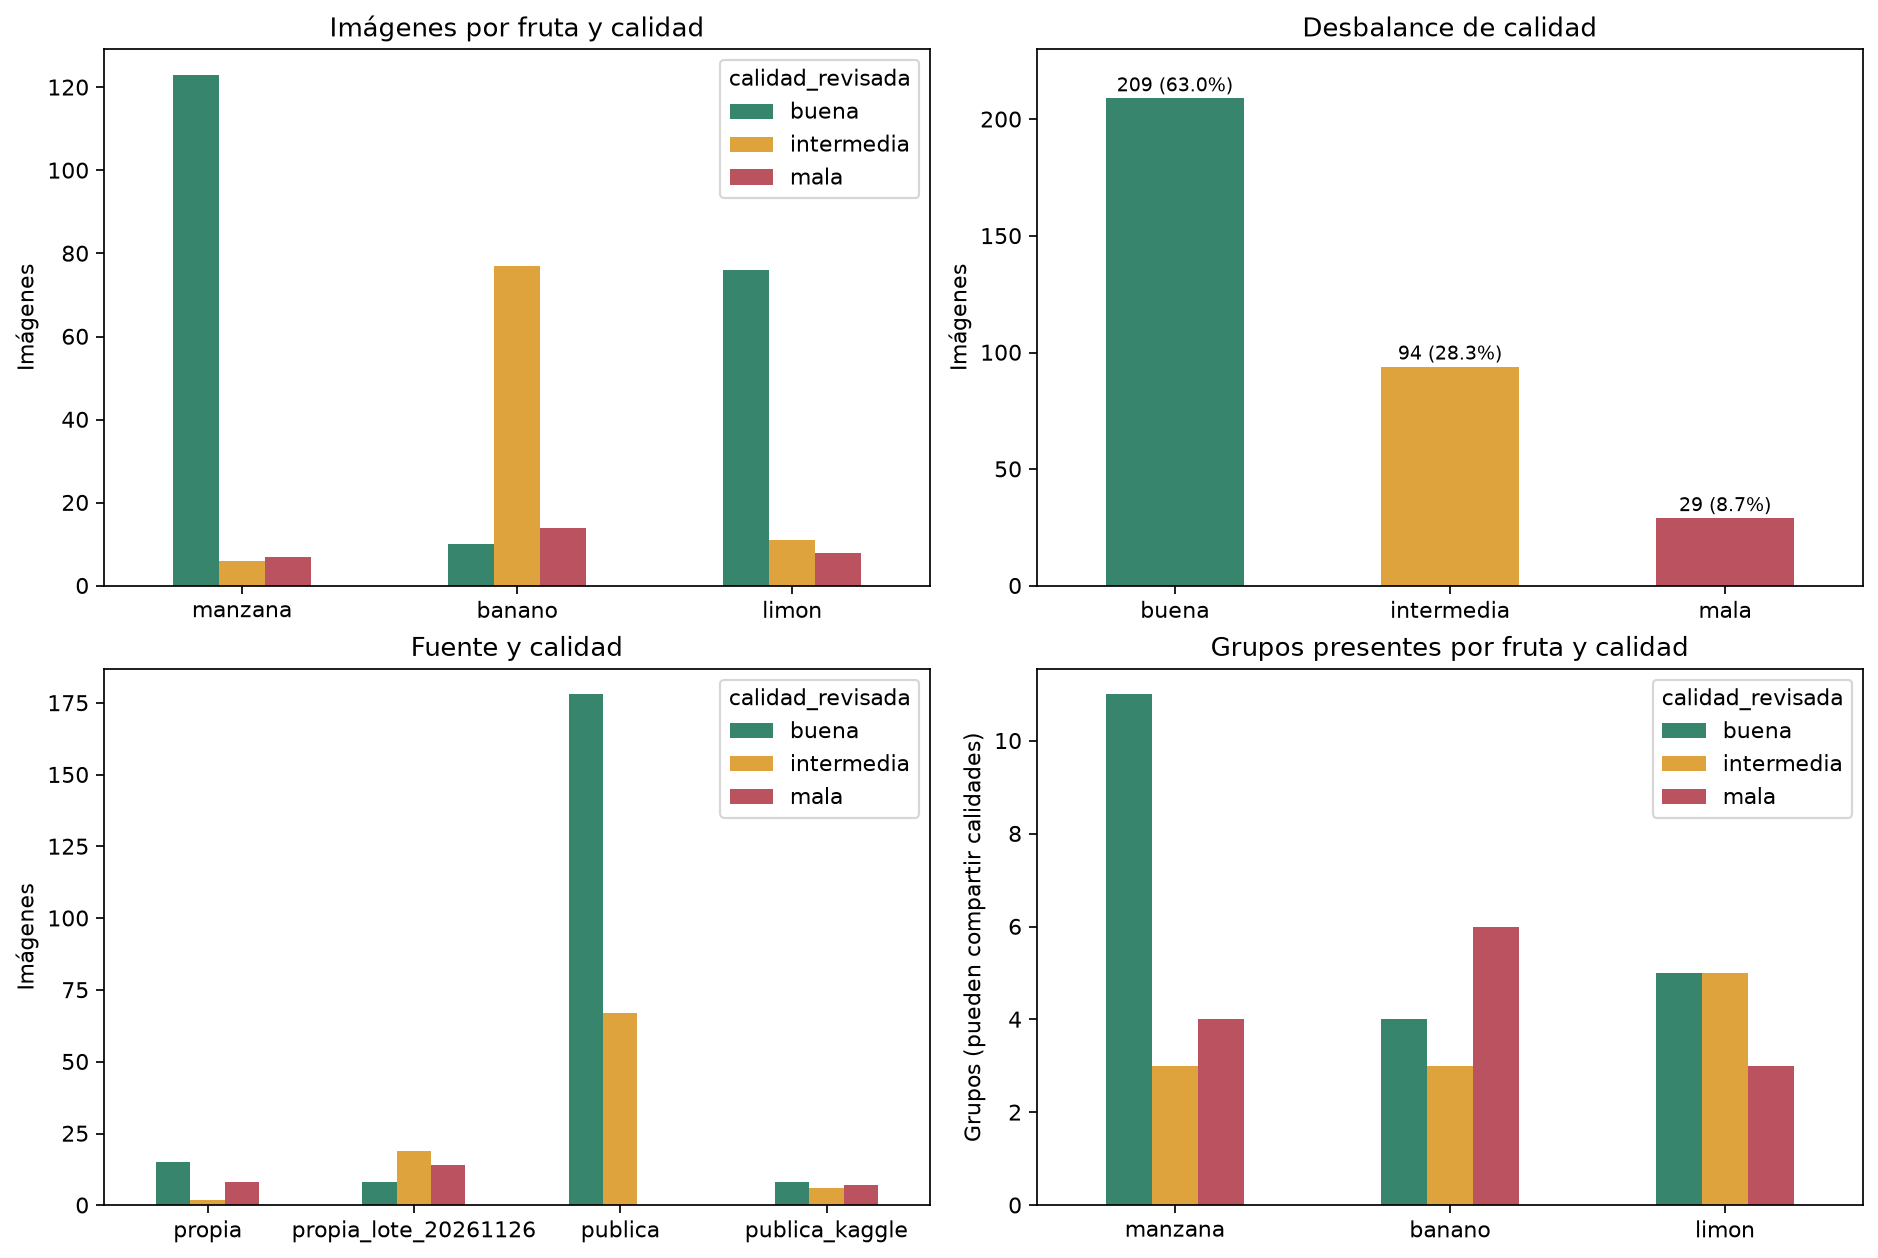

In [2]:
diagnostico, conteos, cobertura, origen = hacer_eda(base, columnas, SALIDA)
display(pd.Series(diagnostico, name='valor').to_frame())
display(conteos.assign(total=conteos.sum(axis=1)))
display(cobertura)
display(origen)
display(Image(filename=str(SALIDA / '01_distribucion_base.png')))

**Lectura:** las clases tienen frecuencias distintas y están asociadas con la fruta y la fuente. Es necesario revisar resultados por clase y por fruta, además del porcentaje global de aciertos. La referencia mayoritaria permite detectar una exactitud aparentemente alta que solo refleje el desbalance.

## 2. Apariencia y características

La galería muestra una selección reproducible por identificador, sin escoger ejemplos por el resultado del modelo. Las distribuciones comparan saturación, brillo, textura y circularidad dentro de cada fruta. Las correlaciones describen redundancias; en este primer entrenamiento conservamos las 43 variables y no seleccionamos características usando las etiquetas de validación. La forma y el tamaño en píxeles siguen siendo relativos al encuadre; no representan centímetros.

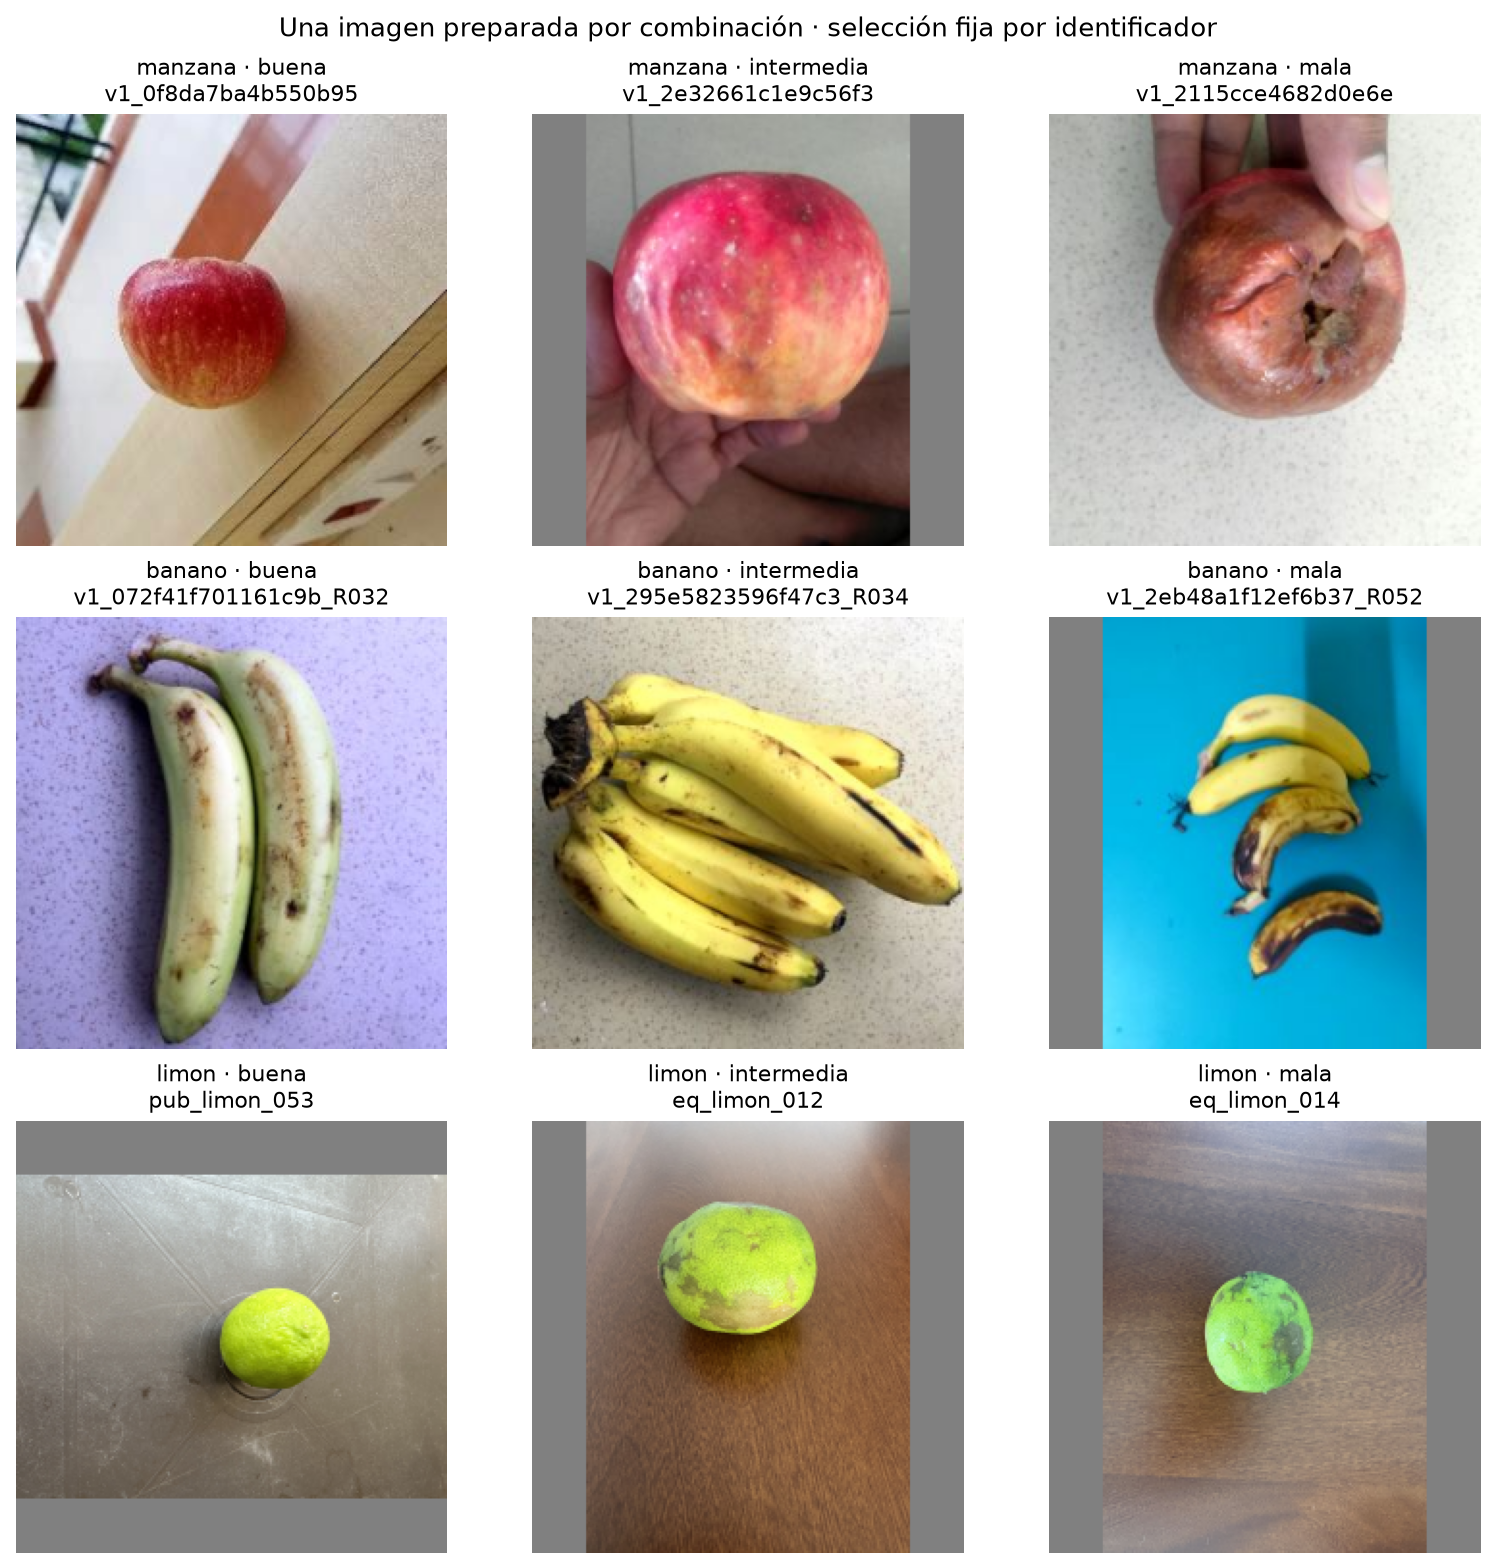

,mean,std,min,50%,max
color_r_media,0.7587,0.1218,0.1938,0.7723,0.9460
color_r_desv,0.1774,0.0461,0.0669,0.1786,0.3211
color_g_media,0.5900,0.1900,0.1019,0.6115,0.9242
color_g_desv,0.1941,0.0370,0.0926,0.1969,0.3124
color_b_media,0.2604,0.0873,0.0485,0.2498,0.7258
color_b_desv,0.1437,0.0351,0.0618,0.1408,0.3233
color_h_seno,0.5765,0.2948,-0.1279,0.6924,0.9835
color_h_coseno,0.6825,0.2526,-0.3523,0.6906,0.9932
color_hist_h_0,0.4820,0.4053,0.0001,0.3909,0.9995
color_hist_h_1,0.4638,0.4226,0.0000,0.4733,0.9997


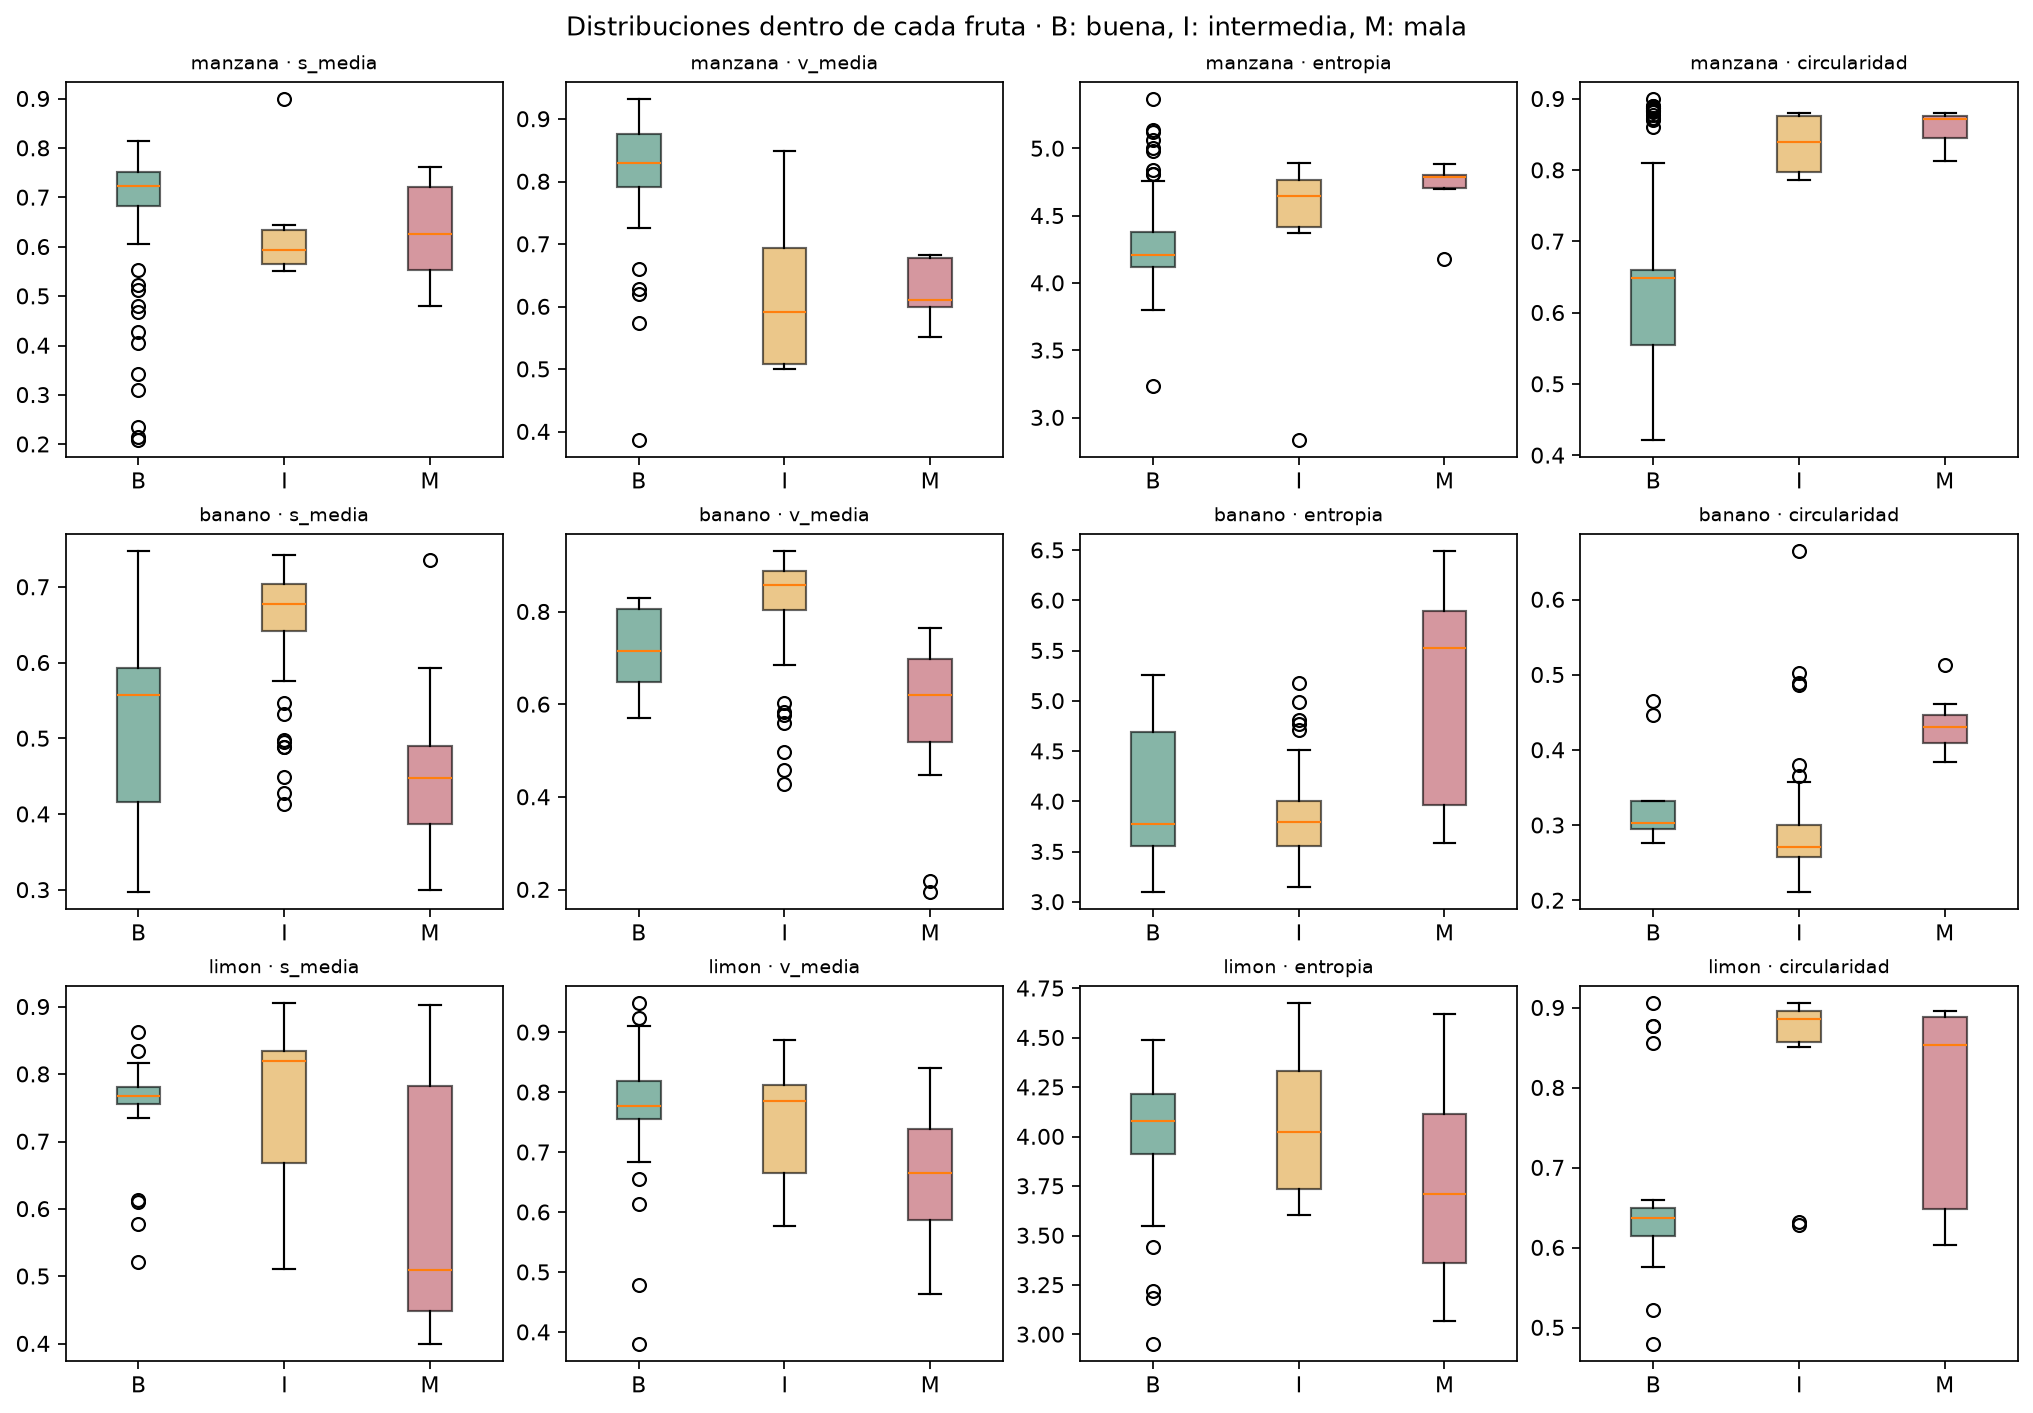

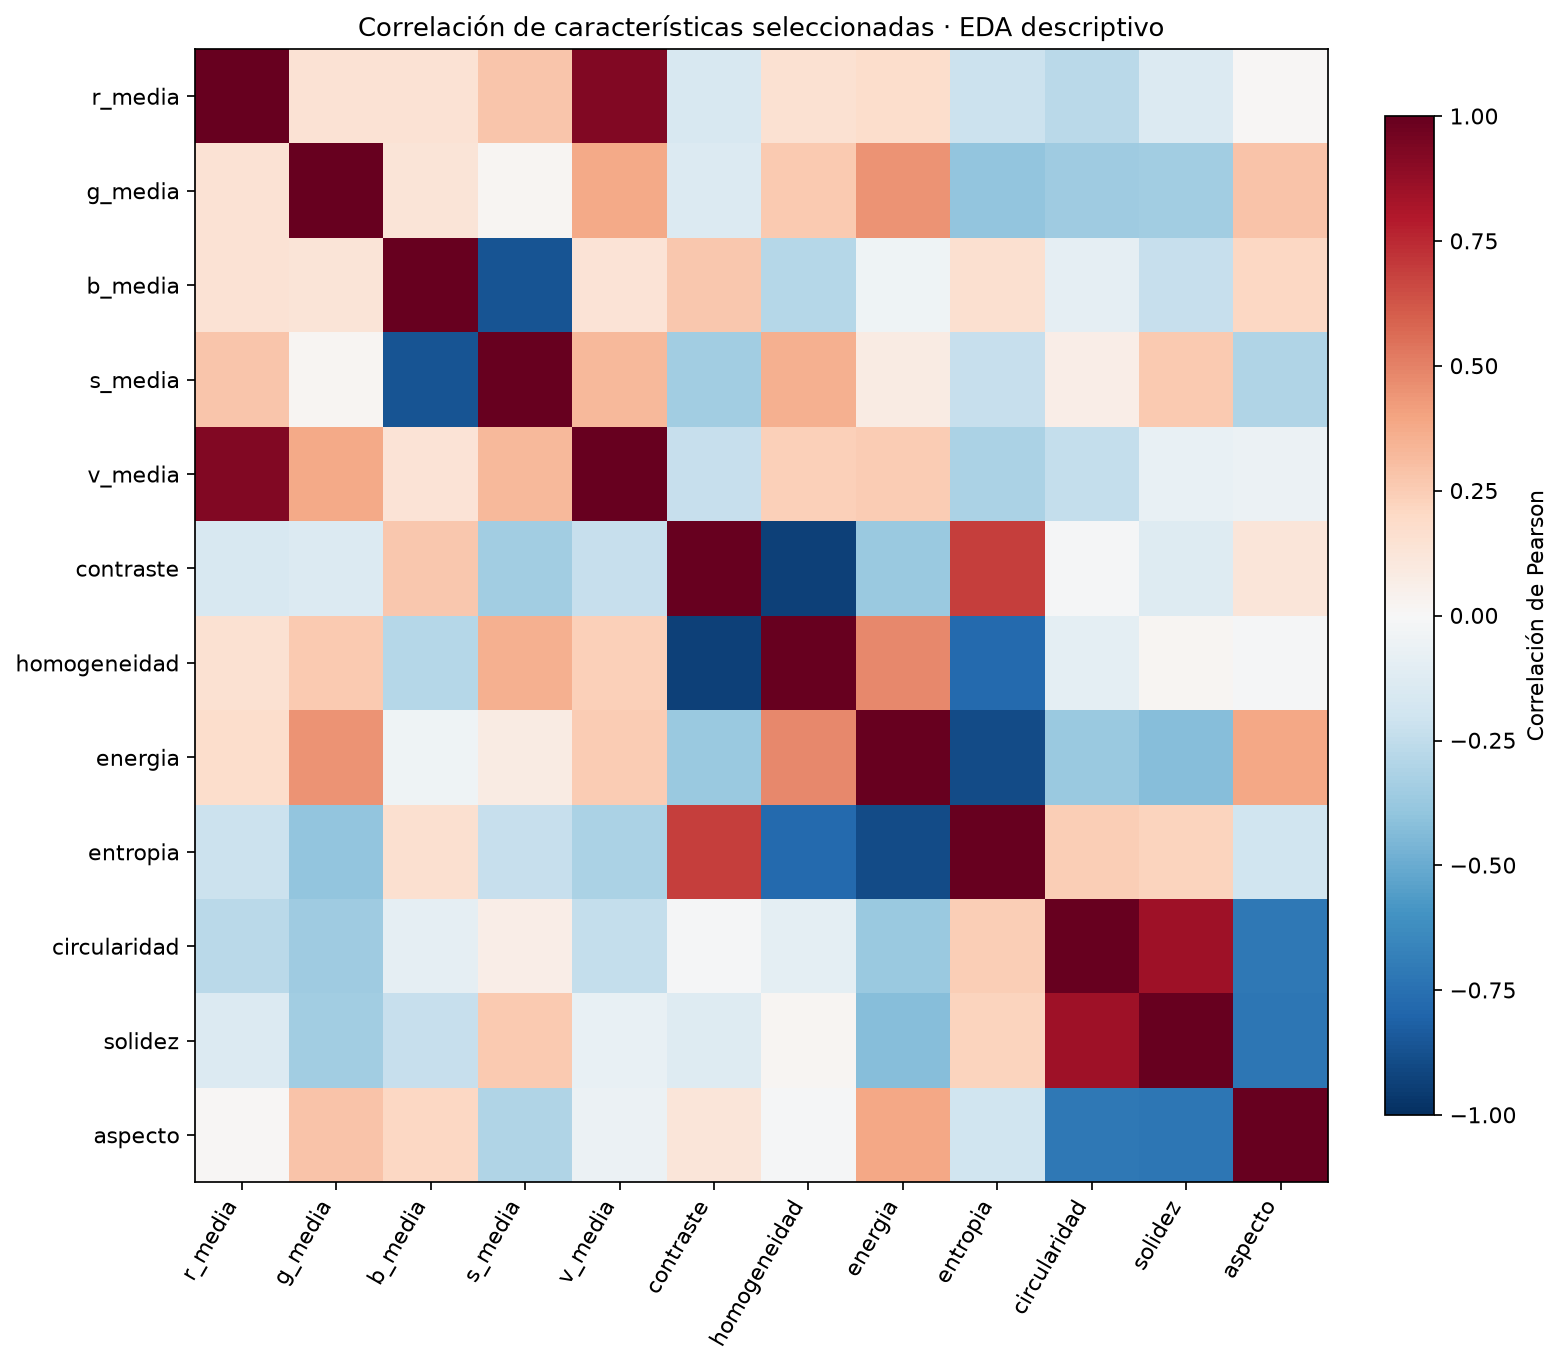

In [3]:
display(Image(filename=str(SALIDA / '04_ejemplos_base.png')))
display(base[columnas].describe().T[['mean', 'std', 'min', '50%', 'max']].round(4))
display(Image(filename=str(SALIDA / '02_distribuciones_caracteristicas.png')))
display(Image(filename=str(SALIDA / '03_correlaciones.png')))

## 3. Validación por grupos

Cada imagen estará una vez en validación y dos veces en entrenamiento, siempre junto con su grupo. El escalador de SVM se ajustará únicamente con las filas de entrenamiento de cada pliegue. Se comprueba que las tres calidades globales estén presentes en ambos lados; algunas combinaciones específicas de fruta y calidad tienen pocos grupos y pueden faltar. Se exporta esa cobertura para interpretar los resultados.

In [4]:
particiones, pliegue_imagen, cobertura_cv = crear_pliegues(base)
distribucion_cv = pd.crosstab(pd.Series(pliegue_imagen, name='pliegue'), base.calidad_revisada).reindex(columns=CALIDADES)
display(distribucion_cv)
sin_cobertura = cobertura_cv.loc[cobertura_cv.imagenes == 0]
print(f'Combinaciones fruta-calidad ausentes en alguna etapa: {len(sin_cobertura)} (de {len(cobertura_cv)}).')
display(sin_cobertura)
for train, val in particiones:
    assert not set(base.iloc[train].grupo_particion) & set(base.iloc[val].grupo_particion)
print('Comprobado: no hay grupos compartidos entre entrenamiento y validación.')

calidad_revisada,buena,intermedia,mala
pliegue,,,
1,105,11,10
2,79,16,11
3,25,67,8


Combinaciones fruta-calidad ausentes en alguna etapa: 5 (de 54).


,pliegue,etapa,fruta,calidad,imagenes,grupos
12,1,validacion,banano,buena,0,0
13,1,validacion,banano,intermedia,0,0
46,3,validacion,manzana,intermedia,0,0
52,3,validacion,limon,intermedia,0,0
53,3,validacion,limon,mala,0,0


Comprobado: no hay grupos compartidos entre entrenamiento y validación.


## 4. Entrenamiento y comparación

- **SVM:** `StandardScaler` y `SVC(C=1, kernel="rbf", gamma="scale", class_weight="balanced")`.
- **Random Forest:** 300 árboles, mínimo de 2 imágenes por hoja, pesos de clase balanceados y semilla 42.
- **Referencia:** clase mayoritaria aprendida en cada entrenamiento.

La tabla reúne las predicciones fuera del entrenamiento (**OOF**): cada imagen fue predicha por un modelo que no vio su grupo. F1 macro y recall macro dan el mismo peso a las tres calidades. También calculamos métricas con peso total igual por grupo para mostrar la sensibilidad al tamaño de las campañas; no son intervalos de confianza ni grupos físicos completamente verificados.

,modelo,imagenes,exactitud,f1_macro,recall_macro,exactitud_peso_grupo,f1_macro_peso_grupo,recall_macro_peso_grupo
0,Referencia_mayoritaria,332,0.6295,0.2575,0.3333,0.4398,0.2036,0.3333
1,SVM,332,0.3795,0.3180,0.3405,0.3019,0.2945,0.2919
2,Random_Forest,332,0.4247,0.3963,0.4205,0.3726,0.3415,0.3641


,modelo,pliegue,n_train,n_validacion,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,1,206,126,0.8333,0.3030,0.3333
1,Referencia_mayoritaria,2,226,106,0.7453,0.2847,0.3333
2,Referencia_mayoritaria,3,232,100,0.2500,0.1333,0.3333
3,SVM,1,206,126,0.6190,0.3009,0.3381
4,SVM,2,226,106,0.1321,0.1613,0.2370
5,SVM,3,232,100,0.3400,0.2419,0.2309
6,Random_Forest,1,206,126,0.8651,0.5226,0.5571
7,Random_Forest,2,226,106,0.1604,0.2266,0.3445
8,Random_Forest,3,232,100,0.1500,0.2146,0.2548


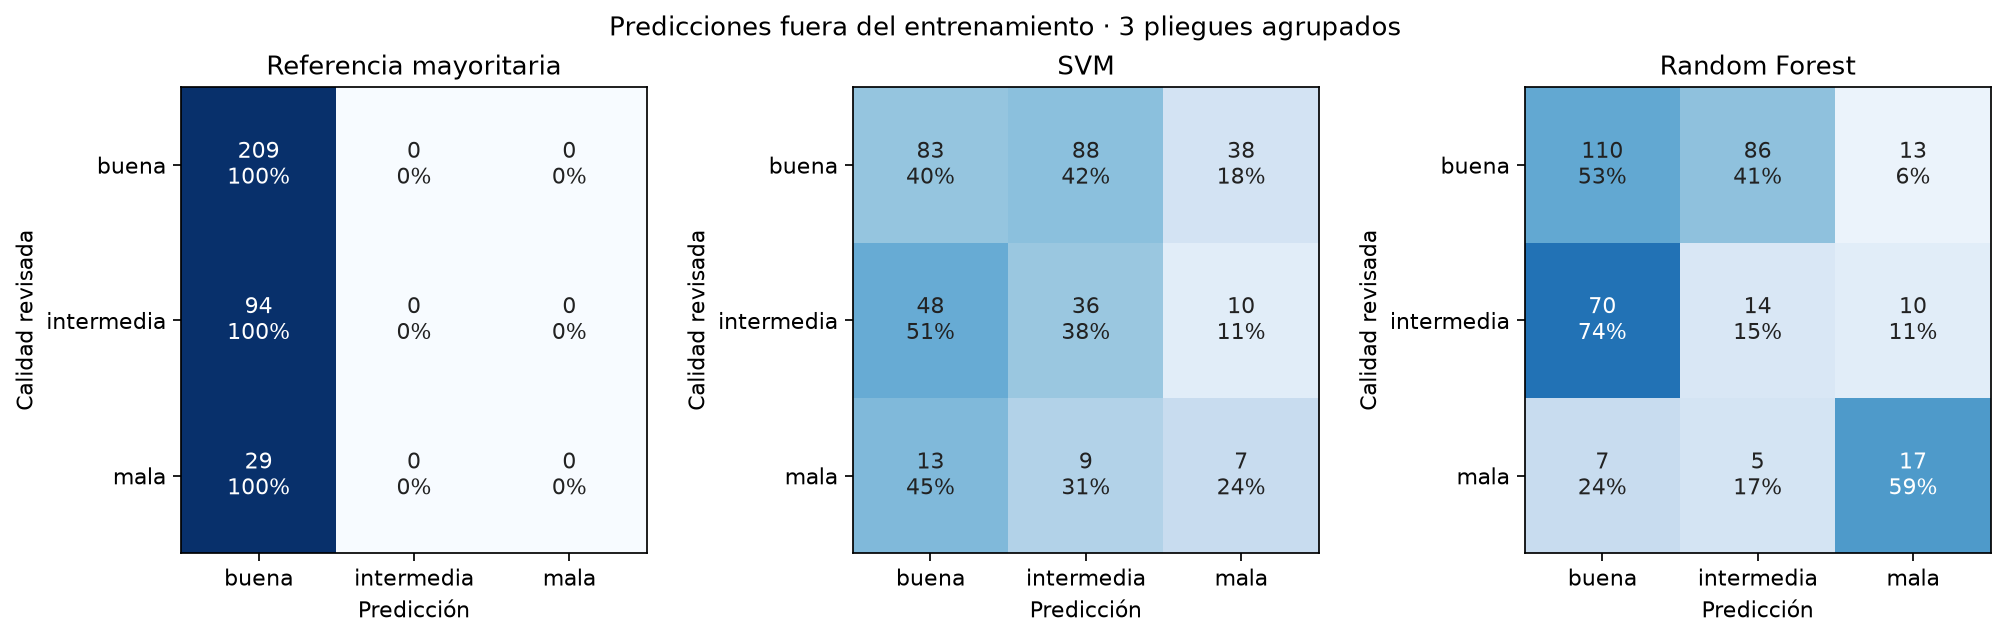

In [5]:
import os
if os.environ.get('FRUTAS_USAR_RESULTADOS') == '1':
    import joblib
    assert joblib.load(CHECKPOINTS / 'random_forest.joblib')['sha_base'] == estado['sha_base']
    tablas = {f.stem: pd.read_csv(f) for f in SALIDA.glob('*.csv')}
    print('Resultados del entrenamiento completo guardado, verificados contra la base actual.')
else:
    tablas = entrenar_y_comparar(base, columnas, estado, SALIDA, CHECKPOINTS)
metricas = tablas['metricas_globales']
display(metricas)
display(tablas['metricas_pliegues'])
display(Image(filename=str(SALIDA / '05_matrices_confusion.png')))

## 5. Errores y comportamiento por fruta y fuente

El recall de una clase indica qué fracción de las imágenes revisadas de esa calidad recupera el modelo. Las métricas por fruta usan siempre las tres calidades, pero algunas celdas contienen solo dos o tres fotografías. Los resultados por fuente proceden de los mismos pliegues mezclados: **no** son una prueba entrenada en público y evaluada exclusivamente en fotos propias.

In [6]:
display(tablas['metricas_por_clase'])
display(tablas['metricas_por_fruta'])
display(tablas['metricas_por_fuente'])
errores = tablas['predicciones_oof'].query("modelo != 'Referencia_mayoritaria' and acierto == False")
display(errores[['modelo', 'id_ejemplar', 'fruta', 'calidad_revisada', 'prediccion', 'pliegue_validacion']].head(15))

,modelo,calidad,imagenes,recall,f1
0,Referencia_mayoritaria,buena,209,1.0000,0.7726
1,Referencia_mayoritaria,intermedia,94,0.0000,0.0000
2,Referencia_mayoritaria,mala,29,0.0000,0.0000
3,SVM,buena,209,0.3971,0.4703
4,SVM,intermedia,94,0.3830,0.3172
5,SVM,mala,29,0.2414,0.1667
6,Random_Forest,buena,209,0.5263,0.5556
7,Random_Forest,intermedia,94,0.1489,0.1407
8,Random_Forest,mala,29,0.5862,0.4928


,modelo,fruta,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,banano,101,0.0990,0.0601,0.3333
1,Referencia_mayoritaria,limon,95,0.8000,0.2963,0.3333
2,Referencia_mayoritaria,manzana,136,0.9044,0.3166,0.3333
3,SVM,banano,101,0.3663,0.2541,0.2281
4,SVM,limon,95,0.0632,0.0437,0.0781
5,SVM,manzana,136,0.6103,0.3178,0.4495
6,Random_Forest,banano,101,0.2178,0.2886,0.2996
7,Random_Forest,limon,95,0.0842,0.1913,0.1988
8,Random_Forest,manzana,136,0.8162,0.4315,0.5254


,modelo,fuente,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,propia,25,0.6000,0.2500,0.3333
1,Referencia_mayoritaria,propia_lote_20261126,41,0.1951,0.1088,0.3333
2,Referencia_mayoritaria,publica,245,0.7265,0.2805,0.3333
3,Referencia_mayoritaria,publica_kaggle,21,0.3810,0.1839,0.3333
4,SVM,propia,25,0.4000,0.3896,0.5694
5,SVM,propia_lote_20261126,41,0.1951,0.1939,0.2253
6,SVM,publica,245,0.4204,0.2853,0.2860
7,SVM,publica_kaggle,21,0.2381,0.2340,0.2341
8,Random_Forest,propia,25,0.4000,0.3911,0.5694
9,Random_Forest,propia_lote_20261126,41,0.3415,0.3244,0.3440


,modelo,id_ejemplar,fruta,calidad_revisada,prediccion,pliegue_validacion
332,SVM,072f41f701161c9b_R032,banano,buena,mala,2
333,SVM,0f8da7ba4b550b95,manzana,buena,mala,3
335,SVM,295e5823596f47c3_R034,banano,intermedia,mala,2
336,SVM,2d1b73a74c463d28,banano,intermedia,mala,2
337,SVM,2e32661c1e9c56f3,manzana,intermedia,buena,1
338,SVM,2eb48a1f12ef6b37_R052,banano,mala,intermedia,3
340,SVM,3ccf6af65a1a3e15,banano,mala,buena,1
341,SVM,4fce4c3a8a985083_R050,banano,buena,mala,3
342,SVM,810428c750ecb8cb,manzana,intermedia,mala,1
344,SVM,c459eec8a18c78dc,manzana,mala,buena,2


## 6. Prototipos guardados y conclusión del primer experimento

Después de evaluar, ajustamos SVM y Random Forest sobre todas las imágenes de la base vigente y guardamos cada modelo con su orden de características, clases y huella de la base. Las métricas anteriores pertenecen a la validación por grupos, no al ajuste con todas las imágenes. Los archivos `.joblib` deben cargarse solo desde fuentes confiables.

Para inferir con una imagen nueva se aplica primero la misma preparación y extracción de características de los cuadernos 02/04; estos prototipos reciben una tabla con las 43 características, no la fotografía directamente.

In [7]:
import joblib

paquete = joblib.load(CHECKPOINTS / 'random_forest.joblib')
assert paquete['sha_base'] == estado['sha_base']
ejemplo = base.loc[[0], paquete['caracteristicas']]
print('Ejemplo de uso del prototipo RF:', paquete['modelo'].predict(ejemplo)[0])
print('Esta predicción de ejemplo no se usa para calcular métricas.')
print('Modelos guardados:', [p.name for p in CHECKPOINTS.glob('*.joblib')])
print('Tablas y figuras:', SALIDA)

comparables = metricas.query("modelo != 'Referencia_mayoritaria'")
mejor = comparables.sort_values('f1_macro', ascending=False).iloc[0]
referencia = metricas.query("modelo == 'Referencia_mayoritaria'").iloc[0]
display(Markdown(
    f"**Resultado observado:** {mejor.modelo.replace('_', ' ')} obtiene el mayor F1 macro OOF "
    f"de los dos modelos ({mejor.f1_macro:.3f}); la referencia obtiene {referencia.f1_macro:.3f}. "
    "La tabla por clase y los tres pliegues permiten revisar dónde falla y cuánto cambia el resultado. "
    "Con este balance y cobertura, esta comparación inicia el desarrollo y no permite declarar un ganador definitivo. "
    "El siguiente experimento puede ajustar hiperparámetros dentro de los pliegues de entrenamiento "
    "y sumar ejemplos de las calidades escasas, conservando este resultado como referencia."
))

Ejemplo de uso del prototipo RF: buena
Esta predicción de ejemplo no se usa para calcular métricas.
Modelos guardados: ['random_forest.joblib', 'svm.joblib']
Tablas y figuras: C:\Users\juanp\Documents\Algoritmos&ProgramacionIII\proyecto_estado_frutas\experiments\results\eda_modelos


**Resultado observado:** Random Forest obtiene el mayor F1 macro OOF de los dos modelos (0.396); la referencia obtiene 0.258. La tabla por clase y los tres pliegues permiten revisar dónde falla y cuánto cambia el resultado. Con este balance y cobertura, esta comparación inicia el desarrollo y no permite declarar un ganador definitivo. El siguiente experimento puede ajustar hiperparámetros dentro de los pliegues de entrenamiento y sumar ejemplos de las calidades escasas, conservando este resultado como referencia.